# Deep Learning for Loan Prediction
**ASAP Final Deliverable**

This notebook replaces the Decision Tree baseline with a custom deep learning (Multi-Layer Perceptron) model built in PyTorch, trained to predict loan approval status from applicant attributes.

## Section 1: Data Loading and Visualization

In [1]:
# Cell [1]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import warnings
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Torch version:", torch.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Torch version: 2.13.0+cu130
Using device: cpu


In [2]:
# Cell [2]
train_df = pd.read_csv("train.csv")
print("Shape:", train_df.shape)
train_df.head()


Shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
# Cell [3]
train_df.info()
print("\nMissing values per column:\n", train_df.isnull().sum())
train_df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB

Missing values per column:
 Loan_ID               0
Gender               13
Married               3
Dependents           15
Ed

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
count,614,601,611,599,614,582,614.000000,614.000000,592.000000,600.00000,564.000000,614,614
unique,614,2,2,4,2,2,NaN,NaN,NaN,NaN,NaN,3,2
top,LP001002,Male,Yes,0,Graduate,No,NaN,NaN,NaN,NaN,NaN,Semiurban,Y
freq,1,489,398,345,480,500,NaN,NaN,NaN,NaN,NaN,233,422
mean,NaN,NaN,NaN,NaN,NaN,NaN,5403.459283,1621.245798,146.412162,342.00000,0.842199,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,6109.041673,2926.248369,85.587325,65.12041,0.364878,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,150.000000,0.000000,9.000000,12.00000,0.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2877.500000,0.000000,100.000000,360.00000,1.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,3812.500000,1188.500000,128.000000,360.00000,1.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,5795.000000,2297.250000,168.000000,360.00000,1.000000,NaN,NaN


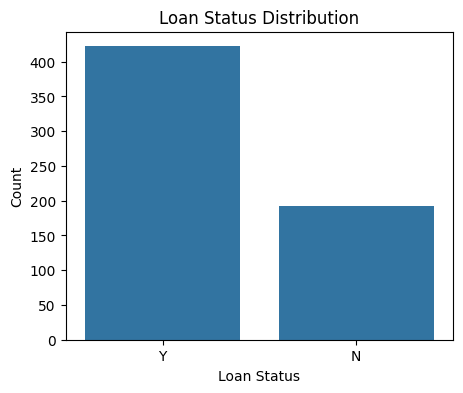

Loan_Status
Y    0.687296
N    0.312704
Name: proportion, dtype: float64


In [4]:
# Cell [4]
plt.figure(figsize=(5,4))
sns.countplot(x='Loan_Status', data=train_df)
plt.title("Loan Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Count")
plt.show()

print(train_df['Loan_Status'].value_counts(normalize=True))


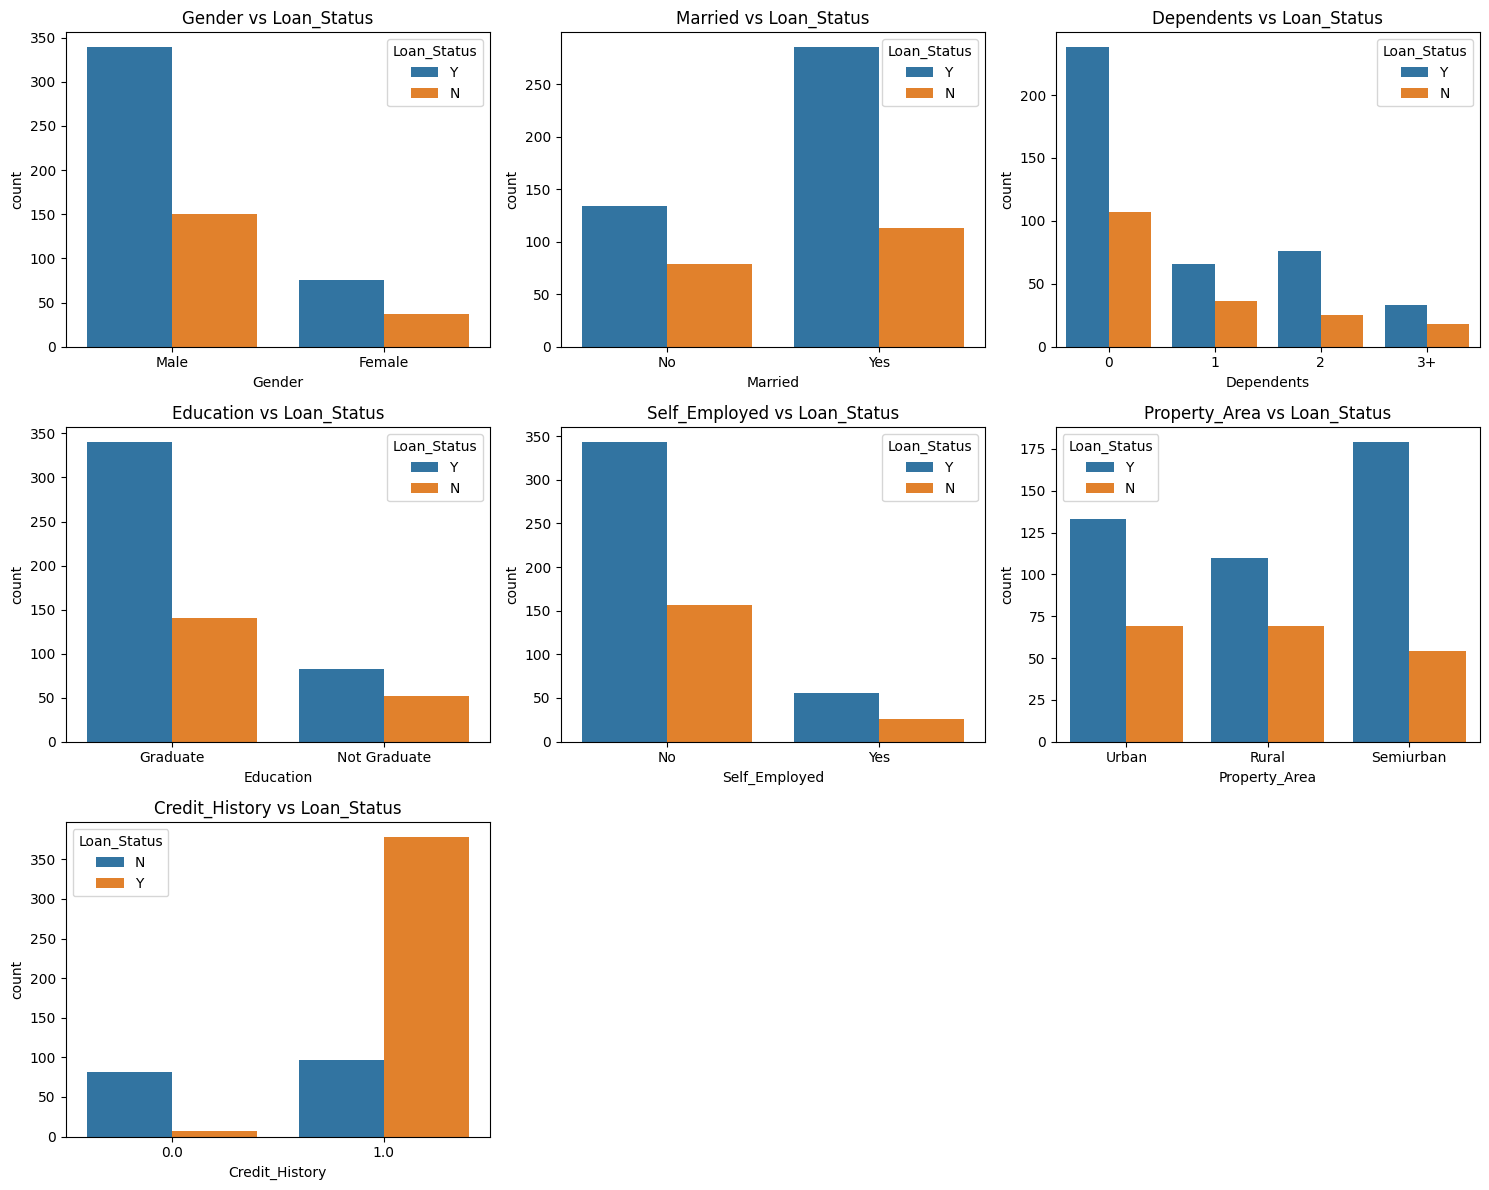

In [5]:
# Cell [5]
categorical_cols = ['Gender', 'Married', 'Dependents', 'Education',
                     'Self_Employed', 'Property_Area', 'Credit_History']

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(categorical_cols):
    sns.countplot(x=col, hue='Loan_Status', data=train_df, ax=axes[i])
    axes[i].set_title(f"{col} vs Loan_Status")
for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()


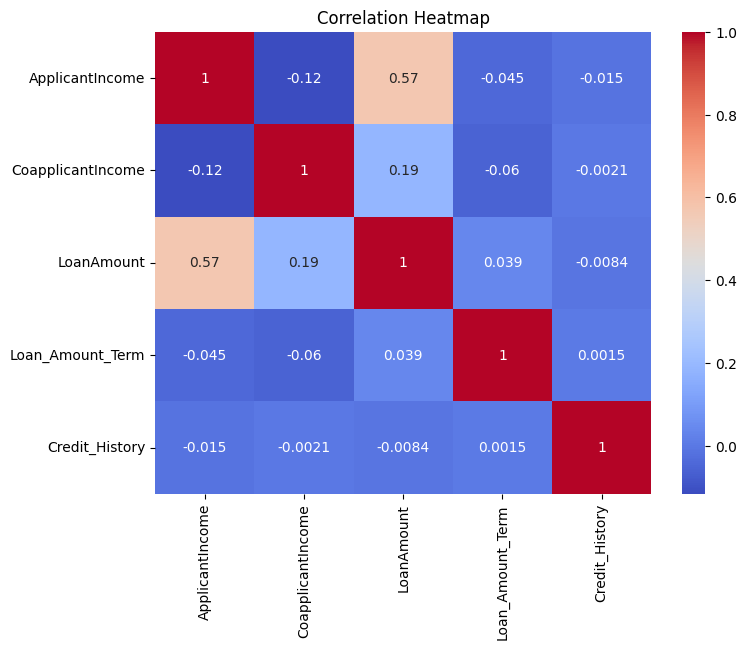

In [6]:
# Cell [6]
numeric_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
                 'Loan_Amount_Term', 'Credit_History']

plt.figure(figsize=(8,6))
sns.heatmap(train_df[numeric_cols].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()


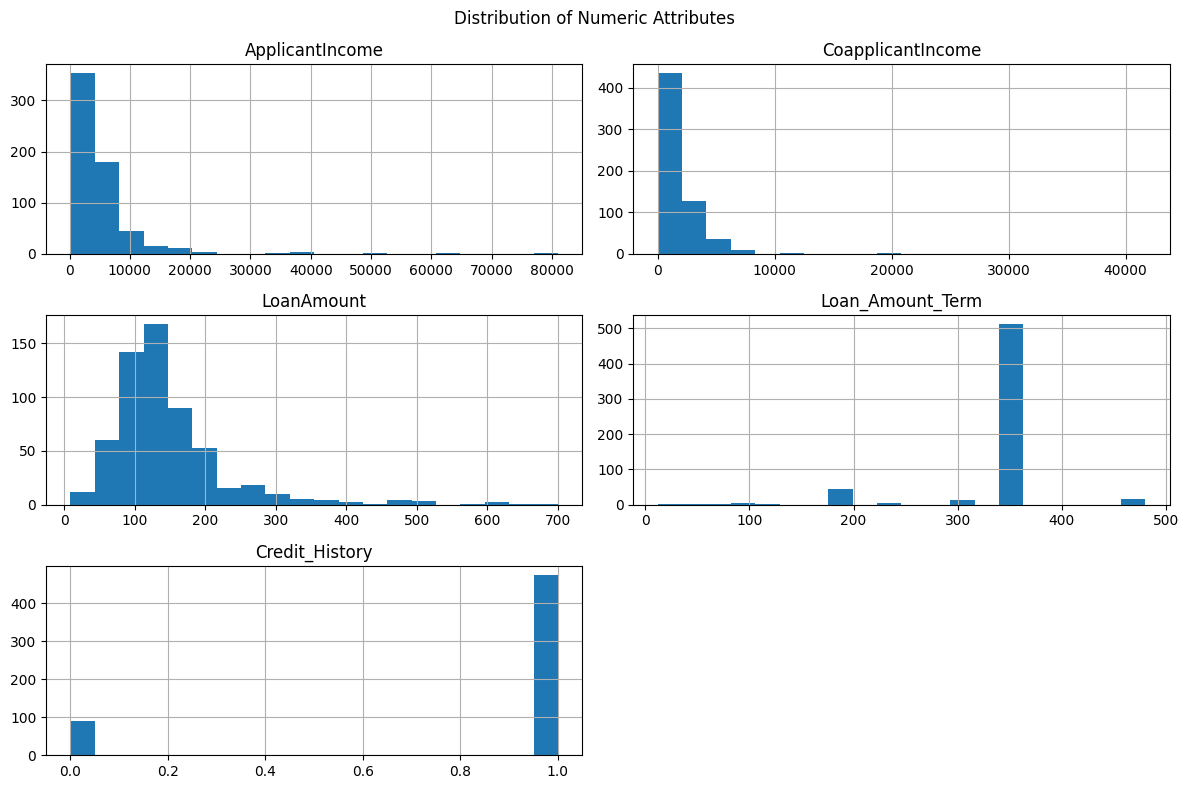

In [7]:
# Cell [8]
train_df[numeric_cols].hist(bins=20, figsize=(12,8))
plt.suptitle("Distribution of Numeric Attributes")
plt.tight_layout()
plt.show()


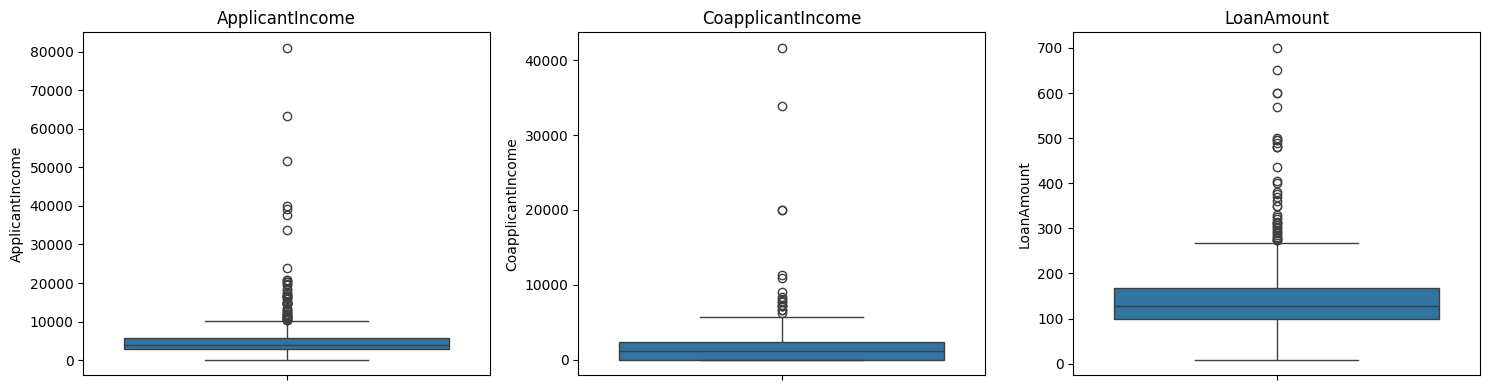

In [8]:
# Cell [9]
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for i, col in enumerate(['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']):
    sns.boxplot(y=train_df[col], ax=axes[i])
    axes[i].set_title(col)
plt.tight_layout()
plt.show()


## Section 1 (cont.): Preprocessing

In [9]:
# Cell [11]
df = train_df.copy()

# Categorical: fill with mode
for col in ['Gender', 'Married', 'Dependents', 'Self_Employed', 'Credit_History']:
    df[col] = df[col].fillna(df[col].mode()[0])

# Numeric: fill with median
for col in ['LoanAmount', 'Loan_Amount_Term']:
    df[col] = df[col].fillna(df[col].median())

print(df.isnull().sum())


Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


In [10]:
# Cell [12]
df['Dependents'] = df['Dependents'].replace('3+', 3).astype(int)

label_cols = ['Gender', 'Married', 'Education', 'Self_Employed',
              'Property_Area', 'Loan_Status']
encoders = {}
for col in label_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le

df.head()


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,1,0,0,0,0,5849,0.0,128.0,360.0,1.0,2,1
1,LP001003,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,0,0
2,LP001005,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,2,1
3,LP001006,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,2,1
4,LP001008,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,2,1


In [11]:
# Cell [13]
scale_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']
scaler = StandardScaler()
df[scale_cols] = scaler.fit_transform(df[scale_cols])
df.head()


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,1,0,0,0,0,0.072991,-0.554487,-0.211241,0.273231,1.0,2,1
1,LP001003,1,1,1,0,0,-0.134412,-0.038732,-0.211241,0.273231,1.0,0,0
2,LP001005,1,1,0,0,1,-0.393747,-0.554487,-0.948996,0.273231,1.0,2,1
3,LP001006,1,1,0,1,0,-0.462062,0.251980,-0.306435,0.273231,1.0,2,1
4,LP001008,1,0,0,0,0,0.097728,-0.554487,-0.056551,0.273231,1.0,2,1


## Section 1 (cont.): Input Attribute Selection

In [12]:
# Cell [16]
feature_cols = ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
                 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
                 'Loan_Amount_Term', 'Credit_History', 'Property_Area']

print("Selected input attributes:", feature_cols)
print("Number of input features:", len(feature_cols))


Selected input attributes: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']
Number of input features: 11


In [13]:
# Cell [17]
# Alternate, reduced feature set used later for the feature-selection experiment
feature_set_full = feature_cols
feature_set_reduced = ['Credit_History', 'Gender', 'Married', 'Education',
                        'ApplicantIncome', 'LoanAmount']

X_full = df[feature_set_full].values.astype(np.float32)
y_all  = df['Loan_Status'].values.astype(np.float32)

X_train_full, X_val_full, y_train, y_val = train_test_split(
    X_full, y_all, test_size=0.2, random_state=SEED, stratify=y_all
)
print("Train:", X_train_full.shape, " Val:", X_val_full.shape)


Train: (491, 11)  Val: (123, 11)


## Section 2: Model Definition, Training, and Evaluation

The Decision Tree from the original helper notebook (Cell [18]) is replaced below with a custom feed-forward neural network (MLP) implemented in PyTorch.

In [14]:
# Cell [18] - Deep learning model (replaces Decision Tree)
class LoanDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


class LoanMLP(nn.Module):
    """
    Fully-connected feed-forward network for binary loan approval classification.
    Architecture: Input -> 64 -> 32 -> 16 -> 1 (logit)
    Activation: ReLU (used consistently across all hidden layers)
    """
    def __init__(self, input_dim):
        super(LoanMLP, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )
    def forward(self, x):
        return self.net(x)

model = LoanMLP(input_dim=len(feature_set_full)).to(device)
print(model)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable parameters:", total_params)


LoanMLP(
  (net): Sequential(
    (0): Linear(in_features=11, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)
Trainable parameters: 3393


In [15]:
# Cell [10] - Loss function and optimizer
criterion = nn.BCEWithLogitsLoss()   # Binary Cross-Entropy with sigmoid applied internally
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)


In [16]:
# Cell [11] - Training loop
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=60):
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb).squeeze(1)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        model.eval()
        val_loss, correct = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb).squeeze(1)
                loss = criterion(logits, yb)
                val_loss += loss.item() * xb.size(0)
                preds = (torch.sigmoid(logits) > 0.5).float()
                correct += (preds == yb).sum().item()
        val_loss /= len(val_loader.dataset)
        val_acc = correct / len(val_loader.dataset)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        if (epoch+1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | "
                  f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")
    return history

train_ds_full = LoanDataset(X_train_full, y_train)
val_ds_full   = LoanDataset(X_val_full, y_val)
train_loader_full = DataLoader(train_ds_full, batch_size=32, shuffle=True)
val_loader_full   = DataLoader(val_ds_full, batch_size=32, shuffle=False)

history = train_model(model, train_loader_full, val_loader_full, criterion, optimizer, epochs=60)


Epoch 1/60 | Train Loss: 0.6727 | Val Loss: 0.6594 | Val Acc: 0.6911


Epoch 10/60 | Train Loss: 0.5146 | Val Loss: 0.4604 | Val Acc: 0.8455


Epoch 20/60 | Train Loss: 0.4365 | Val Loss: 0.4298 | Val Acc: 0.8293


Epoch 30/60 | Train Loss: 0.4089 | Val Loss: 0.4494 | Val Acc: 0.8293
Epoch 40/60 | Train Loss: 0.3742 | Val Loss: 0.4843 | Val Acc: 0.7805


Epoch 50/60 | Train Loss: 0.3403 | Val Loss: 0.5165 | Val Acc: 0.7480
Epoch 60/60 | Train Loss: 0.3100 | Val Loss: 0.5630 | Val Acc: 0.8211


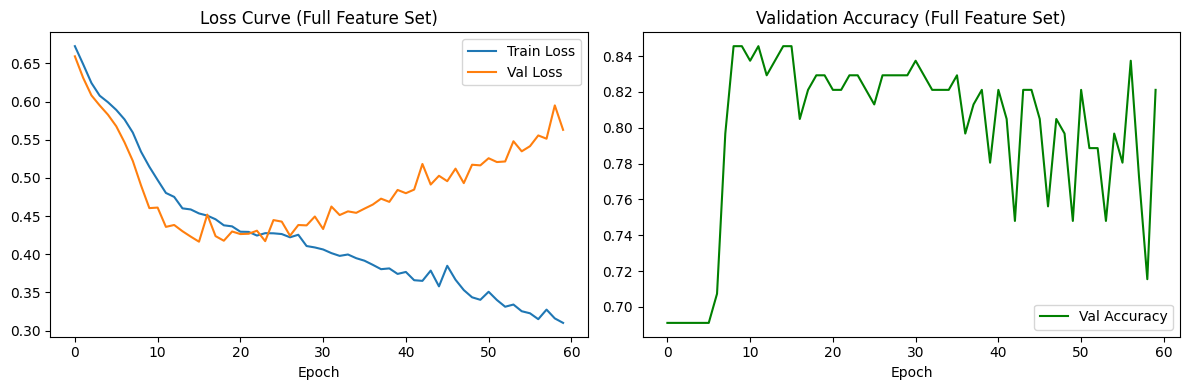

In [17]:
# Cell [12] - Training curves
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(history['train_loss'], label='Train Loss')
axes[0].plot(history['val_loss'], label='Val Loss')
axes[0].set_title("Loss Curve (Full Feature Set)")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history['val_acc'], label='Val Accuracy', color='green')
axes[1].set_title("Validation Accuracy (Full Feature Set)")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()


In [18]:
# Cell [13] - Final evaluation on full feature set
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in val_loader_full:
        xb = xb.to(device)
        logits = model(xb).squeeze(1)
        preds = (torch.sigmoid(logits) > 0.5).float().cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

full_feature_acc = accuracy_score(all_labels, all_preds)
print("Final Validation Accuracy (Full Feature Set):", full_feature_acc)
print("\nConfusion Matrix:\n", confusion_matrix(all_labels, all_preds))
print("\nClassification Report:\n", classification_report(all_labels, all_preds))


Final Validation Accuracy (Full Feature Set): 0.8211382113821138

Confusion Matrix:
 [[21 17]
 [ 5 80]]

Classification Report:
               precision    recall  f1-score   support

         0.0       0.81      0.55      0.66        38
         1.0       0.82      0.94      0.88        85

    accuracy                           0.82       123
   macro avg       0.82      0.75      0.77       123
weighted avg       0.82      0.82      0.81       123



## Experiment: Effect of Feature Selection

To study the effect of input attribute selection on performance (required for the report's Experimental Results section), the same model architecture is retrained using the reduced feature set defined in Cell [17].

In [19]:
# Reduced feature set experiment
X_reduced = df[feature_set_reduced].values.astype(np.float32)
X_train_red, X_val_red, y_train_red, y_val_red = train_test_split(
    X_reduced, y_all, test_size=0.2, random_state=SEED, stratify=y_all
)

train_ds_red = LoanDataset(X_train_red, y_train_red)
val_ds_red   = LoanDataset(X_val_red, y_val_red)
train_loader_red = DataLoader(train_ds_red, batch_size=32, shuffle=True)
val_loader_red   = DataLoader(val_ds_red, batch_size=32, shuffle=False)

model_reduced = LoanMLP(input_dim=len(feature_set_reduced)).to(device)
optimizer_red = optim.Adam(model_reduced.parameters(), lr=1e-3, weight_decay=1e-5)

history_red = train_model(model_reduced, train_loader_red, val_loader_red,
                           criterion, optimizer_red, epochs=60)

model_reduced.eval()
preds_red, labels_red = [], []
with torch.no_grad():
    for xb, yb in val_loader_red:
        xb = xb.to(device)
        logits = model_reduced(xb).squeeze(1)
        preds = (torch.sigmoid(logits) > 0.5).float().cpu().numpy()
        preds_red.extend(preds)
        labels_red.extend(yb.numpy())

reduced_feature_acc = accuracy_score(labels_red, preds_red)
print("Final Validation Accuracy (Reduced Feature Set):", reduced_feature_acc)

print("\n--- Summary ---")
print(f"Full feature set  ({len(feature_set_full)} features): {full_feature_acc:.4f}")
print(f"Reduced feature set ({len(feature_set_reduced)} features): {reduced_feature_acc:.4f}")


Epoch 1/60 | Train Loss: 0.7072 | Val Loss: 0.6895 | Val Acc: 0.7154


Epoch 10/60 | Train Loss: 0.5019 | Val Loss: 0.4292 | Val Acc: 0.8537


Epoch 20/60 | Train Loss: 0.4711 | Val Loss: 0.4144 | Val Acc: 0.8537
Epoch 30/60 | Train Loss: 0.4641 | Val Loss: 0.4254 | Val Acc: 0.8455


Epoch 40/60 | Train Loss: 0.4649 | Val Loss: 0.4304 | Val Acc: 0.8211
Epoch 50/60 | Train Loss: 0.4605 | Val Loss: 0.4289 | Val Acc: 0.8211


Epoch 60/60 | Train Loss: 0.4545 | Val Loss: 0.4306 | Val Acc: 0.8211
Final Validation Accuracy (Reduced Feature Set): 0.8211382113821138

--- Summary ---
Full feature set  (11 features): 0.8211
Reduced feature set (6 features): 0.8211


## Section 3: Predictions on the Held-Out Test Set

`test.csv` is the competition-style held-out set and does **not** contain the `Loan_Status` target column, so accuracy cannot be computed on it directly — it is used here only to generate final predictions using the model trained on the full feature set. The same preprocessing (imputation using training-set statistics, label encoding, scaling) is applied for consistency.

In [20]:
# Load and preprocess the held-out test set using TRAIN-fitted statistics
test_df = pd.read_csv("test.csv")
print("Test shape:", test_df.shape)
test_df.head()


Test shape: (367, 12)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001015,Male,Yes,0,Graduate,No,5720,0,110.0,360.0,1.0,Urban
1,LP001022,Male,Yes,1,Graduate,No,3076,1500,126.0,360.0,1.0,Urban
2,LP001031,Male,Yes,2,Graduate,No,5000,1800,208.0,360.0,1.0,Urban
3,LP001035,Male,Yes,2,Graduate,No,2340,2546,100.0,360.0,NaN,Urban
4,LP001051,Male,No,0,Not Graduate,No,3276,0,78.0,360.0,1.0,Urban


In [21]:
# Apply the same preprocessing pipeline fitted on the training data
test_proc = test_df.copy()

# Impute missing values using the modes/medians computed on the TRAINING set
for col in ['Gender', 'Married', 'Dependents', 'Self_Employed', 'Credit_History']:
    test_proc[col] = test_proc[col].fillna(train_df[col].mode()[0])
for col in ['LoanAmount', 'Loan_Amount_Term']:
    test_proc[col] = test_proc[col].fillna(train_df[col].median())

test_proc['Dependents'] = test_proc['Dependents'].replace('3+', 3).astype(int)

# Re-use the LabelEncoders fitted on the training set
for col in ['Gender', 'Married', 'Education', 'Self_Employed', 'Property_Area']:
    test_proc[col] = encoders[col].transform(test_proc[col])

# Re-use the StandardScaler fitted on the training set
test_proc[scale_cols] = scaler.transform(test_proc[scale_cols])

X_test = test_proc[feature_set_full].values.astype(np.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
print("Prepared test features:", X_test_tensor.shape)


Prepared test features: torch.Size([367, 11])


In [22]:
# Generate predictions using the model trained on the full feature set
model.eval()
with torch.no_grad():
    test_logits = model(X_test_tensor).squeeze(1)
    test_probs = torch.sigmoid(test_logits).cpu().numpy()
    test_preds = (test_probs > 0.5).astype(int)

submission = pd.DataFrame({
    'Loan_ID': test_df['Loan_ID'],
    'Loan_Status_Predicted': np.where(test_preds == 1, 'Y', 'N'),
    'Approval_Probability': test_probs.round(4)
})
submission.to_csv('test_predictions.csv', index=False)

print("Predicted approval rate on test set:", (test_preds == 1).mean())
submission.head(10)


Predicted approval rate on test set: 0.8038147138964578


,Loan_ID,Loan_Status_Predicted,Approval_Probability
0,LP001015,Y,0.9282
1,LP001022,Y,0.9009
2,LP001031,Y,0.8812
3,LP001035,Y,0.9029
4,LP001051,Y,0.5616
5,LP001054,Y,0.6517
6,LP001055,Y,0.9010
7,LP001056,N,0.0043
8,LP001059,Y,0.9872
9,LP001067,Y,0.9344
